In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

In [2]:
df = pd.read_csv("../data/processed/foods_cleaned.csv")
features = ["Protein", "Fat", "Carbs", "Fibre"]
X = df[features]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

In [3]:
pca = PCA()
pca.fit(X_scaled)
explained_variance = pca.explained_variance_ratio_

print("Explained variance:")
for i, variance in enumerate(explained_variance):
    print(f"PC{i+1}: {variance:.2%}")

print(
    "\nVariance preserved by first 2 components:",
    f"{explained_variance[:2].sum():.2%}"
)

Explained variance:
PC1: 39.22%
PC2: 25.88%
PC3: 23.05%
PC4: 11.86%

Variance preserved by first 2 components: 65.10%


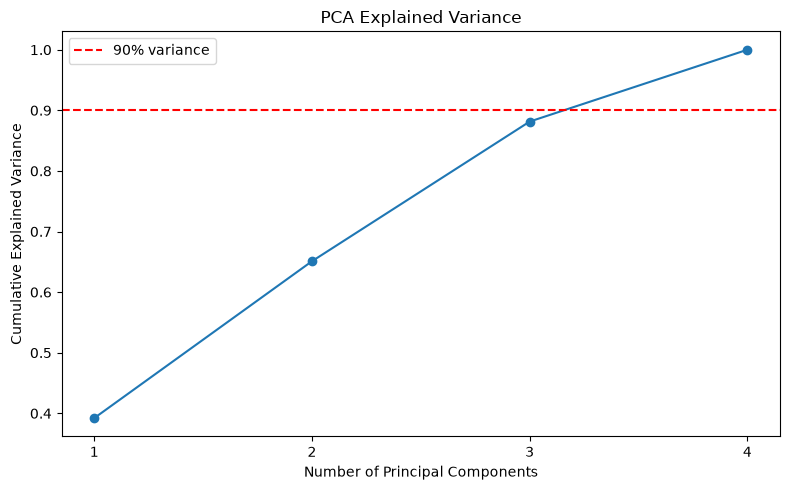

In [ ]:
cumulative_variance = np.cumsum(explained_variance)
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(features) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.90,
    color="red",
    linestyle="--",
    label="90% variance"
)

plt.xticks(range(1, len(features) + 1))
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance")
plt.legend()
plt.tight_layout()
plt.show()

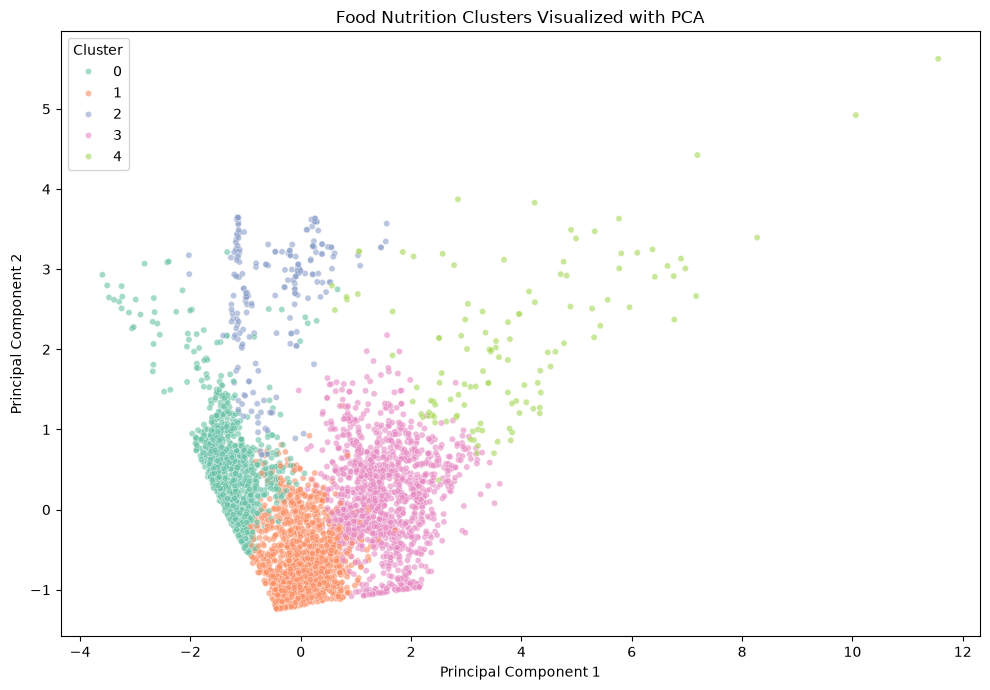

In [ ]:
pca_2d = PCA(n_components=2)
X_pca = pca_2d.fit_transform(X_scaled)
df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set2",
    s=20,
    alpha=0.6
)

plt.title("Food Nutrition Clusters Visualized with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()